# URL Classification with XGBoost

This notebook demonstrates how to classify URLs as malicious or benign using the XGBoost classifier. The process includes data loading, feature engineering, model training with cross-validation, and making predictions on new URLs.

## 1. Importing Libraries

First, we import all the necessary libraries required for data processing, feature engineering, visualization, and model training.

In [1]:
import csv
import itertools
import numpy as np
import os
import re
import string
import hashlib
from urllib.parse import urlparse, parse_qs, urlsplit

import pandas as pd
from joblib import dump, load
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder

import tldextract
# from googlesearch import search  # Uncomment if needed

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn import metrics
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

import ipaddress

# Set plot style for better aesthetics
sns.set(style="whitegrid")

## 2. Configuration

Set up the configuration, including the path to your dataset. Ensure you replace `'./malicious_phish.csv'` dengan path sebenarnya ke file CSV Anda yang berisi data URL.

In [2]:
# Path to your dataset CSV file
DATA_PATH = './malicious_phish.csv'

# Path to save models and encoders
MODEL_PATH = './models/final_xgb_model.pkl'
ENCODER_PATH = './models/target_encoder.pkl'
LABEL_ENCODER_PATH = './models/label_encoder.pkl'

## 3. Feature Engineering Functions

Define a series of functions to extract meaningful features from URLs. These features will help the model distinguish between malicious and benign URLs.

In [3]:
# Daftar TLD terpercaya
TRUSTED_TLDS = {
    # TLD Generik Umum
    'com', 'org', 'net', 'edu', 'gov', 'mil', 'int', 'info', 'co', 'biz', 'me', 'pro',
    'ai', 'dev', 'shop', 'tech', 'store', 'io', 'online', 'site', 'website', 'app', 'club',
    'news', 'health', 'travel', 'blog', 'design', 'media', 'agency',

    # TLD Indonesia yang terpercaya
    'ac.id', 'sch.id', 'go.id', 'or.id', 'web.id', 'co.id', 'my.id', 'ponpes.id',
    'biz.id', 'net.id', 'com.id', 'desa.id',

    # TLD Internasional lainnya yang terpercaya
    # United Kingdom
    'co.uk', 'gov.uk', 'ac.uk', 'org.uk', 'me.uk', 'ltd.uk', 'plc.uk', 'net.uk',

    # Australia
    'edu.au', 'gov.au', 'com.au', 'org.au', 'net.au', 'id.au', 'asn.au',

    # Kanada
    'ca', 'gc.ca', 'co.ca', 'org.ca', 'net.ca',

    # Jepang
    'co.jp', 'ac.jp', 'ad.jp', 'ed.jp', 'go.jp', 'or.jp', 'ne.jp',

    # Jerman
    'de', 'ac.de', 'gov.de', 'edu.de', 'org.de', 'net.de',

    # Prancis
    'fr', 'ac.fr', 'gov.fr', 'asso.fr', 'org.fr', 'com.fr',

    # Amerika Serikat
    'us', 'edu.us', 'gov.us', 'mil.us', 'net.us', 'org.us',

    # Belanda
    'nl', 'bv.nl', 'voornaam.nl', 'achternaam.nl',

    # Singapura
    'sg', 'com.sg', 'net.sg', 'org.sg', 'gov.sg', 'edu.sg',

    # Korea Selatan
    'kr', 'co.kr', 'ne.kr', 'or.kr', 're.kr', 'pe.kr',

    # Cina
    'cn', 'com.cn', 'net.cn', 'org.cn', 'gov.cn', 'edu.cn',

    # Brasil
    'br', 'com.br', 'net.br', 'org.br', 'gov.br', 'edu.br',

    # Rusia
    'ru', 'com.ru', 'net.ru', 'org.ru', 'gov.ru', 'edu.ru',

    # India
    'in', 'co.in', 'net.in', 'org.in', 'firm.in', 'gen.in', 'ind.in',

    # Afrika Selatan
    'za', 'co.za', 'org.za', 'net.za', 'gov.za', 'mil.za', 'ac.za',

    # Uni Emirat Arab
    'ae', 'co.ae', 'net.ae', 'org.ae', 'gov.ae', 'sch.ae',

    # Seluruh Dunia
    'eu', 'asia', 'mobi', 'museum', 'travel', 'jobs', 'name', 'post', 'tel', 'tv', 'cc',
    'me', 'us', 'ca', 'uk', 'de', 'jp', 'fr', 'au', 'cn', 'br', 'ru', 'in', 'za', 'sg',
    'kr', 'it', 'es', 'nl', 'se', 'no', 'fi', 'dk', 'be', 'ch', 'at', 'pl', 'cz', 'hu',
    'sk', 'si', 'ro', 'bg', 'gr', 'tr', 'il', 'my', 'th', 'vn', 'id', 'ph', 'tw', 'hk'
}

In [4]:
def secure_http(url):
    """Count the number of 'https' occurrences in the URL."""
    try:
        return url.lower().count('https')
    except:
        return 0

def url_length(url):
    """Calculate the length of the URL excluding the scheme."""
    try:
        return len(url.replace('http://', '', 1).replace('https://', '', 1))
    except:
        return 0

def find_subdomain(url):
    """Extract the subdomain from the URL."""
    try:
        ext = tldextract.extract(url)
        return ext.subdomain if ext.subdomain else 'missing'
    except:
        return 'missing'

def get_tld_func(url):
    """Extract the top-level domain (TLD) from the URL."""
    try:
        ext = tldextract.extract(url)
        return ext.suffix if ext.suffix else 'missing'
    except:
        return 'missing'

def domain_token_count(url):
    """Count the number of tokens in the domain."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        domain = parsed_url.netloc
        # Remove IPv6 brackets if present
        if domain.startswith('[') and domain.endswith(']'):
            domain = domain[1:-1]
        return len(domain.split('.')) if domain else 0
    except ValueError:
        # Handle invalid IPv6 URLs or other parsing errors
        return 0
    except:
        return 0

def hostname_length(url):
    """Calculate the length of the hostname."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        hostname = parsed_url.hostname
        return len(hostname) if hostname else 0
    except:
        return 0

def extract_root_domain(url):
    """Extract the root domain from the URL."""
    try:
        extracted = tldextract.extract(url)
        return extracted.domain if extracted.domain else 'missing'
    except:
        return 'missing'

def count_dot(url):
    """Count the number of dots in the URL."""
    try:
        return url.count('.')
    except:
        return 0

def no_of_dir(url):
    """Count the number of directories in the URL path."""
    try:
        path = url.split('//', 1)[-1]
        return path.count('/')
    except:
        return 0

def digit_count(url):
    """Count the number of digits in the URL."""
    try:
        return sum(c.isdigit() for c in url)
    except:
        return 0

def letter_count(url):
    """Count the number of letters in the URL."""
    try:
        return sum(c.isalpha() for c in url)
    except:
        return 0

def fd_length(url):
    """Calculate the length of the first directory in the URL path."""
    try:
        urlpath = urlparse(url).path
        return len(urlpath.split('/')[1]) if len(urlpath.split('/')) > 1 else 0
    except:
        return 0

def path_length(url):
    """Calculate the length of the URL path."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        path = parsed_url.path
        return len(path)
    except:
        return 0

def num_query_components(url):
    """Count the number of query components in the URL."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        query = parsed_url.query
        return len(parse_qs(query))
    except:
        return 0

def shortening_service(url):
    """Detect if the URL is using a URL shortening service."""
    try:
        pattern = re.compile(
            r'bit\.ly|goo\.gl|shorte\.st|go2l\.ink|x\.co|ow\.ly|t\.co|tinyurl|cli\.gs|'
            r'yfrog\.com|migre\.me|ff\.im|tiny\.cc|url4\.eu|twit\.ac|su\.pr|twurl\.nl|snipurl\.com|'
            r'short\.to|BudURL\.com|ping\.fm|post\.ly|Just\.as|bkite\.com|snipr\.com|fic\.kr|loopt\.us|'
            r'doiop\.com|short\.ie|kl\.am|wp\.me|rubyurl\.com|om\.ly|to\.ly|bit\.do|lnkd\.in|'
            r'db\.tt|qr\.ae|adata\.ly|bitly\.com|cur\.lv|tinyurl\.com|ity\.im|'
            r'q\.gs|is\.gd|po\.st|bc\.vc|twitthis\.com|u\.to|j\.mp|buzurl\.com|cutt\.us|u\.bb|yourls\.org|'
            r'prettylinkpro\.com|scrnch\.me|filoops\.info|vzturl\.com|qr\.net|1url\.com|tweez\.me|v\.gd|'
            r'tr\.im|link\.zip\.net', re.IGNORECASE)
        return 1 if pattern.search(url) else 0
    except:
        return 0

def abnormal_url(url):
    """
    Detect if the hostname appears more than once in the URL.
    
    Parameters:
    - url (str): The URL to analyze.
    
    Returns:
    - int: 1 jika hostname muncul lebih dari sekali, 0 jika tidak.
    """
    try:
        parsed_url = urlparse(url)
        hostname = parsed_url.hostname
        if not hostname:
            return 0
        
        # Menghitung jumlah kemunculan hostname dalam URL
        occurrences = len(re.findall(re.escape(hostname), url))
        
        # Jika hostname muncul lebih dari sekali, dianggap abnormal
        return 1 if occurrences > 1 else 0
    except Exception as e:
        print(f"Error processing URL '{url}': {e}")
        return 0

def suspicious_words(url):
    """Detect suspicious words in the URL."""
    try:
        pattern = re.compile(
            r'\b(PayPal|login|signin|bank|account|update|free|lucky|service|bonus|ebayisapi|webscr|secure|verify|admin|verification|password|confirm|validate|authenticate|customer|'
            r'click|win|prize|claim|urgent|important|alert|notice|support|help|access|limited|offer|special|deal|promo|discount|gift|reward|survey|contest|trial|membership|'
            r'upgrade|renew|subscription|billing|invoice|statement|transaction|order|purchase|receipt|shipment|delivery|tracking|refund|return|exchange|feedback|review|'
            r'complaint|dispute|resolution|security|protection|privacy|breach|compromise|alert|warning|danger|risk|threat|malware|virus|spyware|phishing|scam|fraud|hoax|'
            r'fake|bogus|deceptive|misleading|trick|trap|bait|switch|spoof|impersonate|identity|theft|steal|hack|breach|exploit|vulnerability|attack|intrusion|penetration|'
            r'expose|leak|disclose|reveal|uncover|discover|detect|identify|trace|track|monitor|observe|watch|spy|snoop|eavesdrop|intercept|capture|record|'
            r'log|store|save|archive|backup|copy|duplicate|replicate|mirror|clone|emulate|simulate|imitate|mimic|reproduce|duplicate|copy|paste|cut|edit|modify|'
            r'alter|change|transform|convert|translate|transcribe|encode|decode|encrypt|decrypt|compress|decompress|zip|unzip|archive|extract|unpack|package|bundle|wrap|'
            r'unwrap|unbundle|unpack|install|uninstall|setup|configure|customize|personalize|optimize|tune|adjust|calibrate|fine-tune|balance|equalize|normalize|standardize|'
            r'validate|verify|authenticate|authorize|approve|certify|accredit|license|register|enroll|subscribe|sign|join|apply|request|submit|send|receive|accept|reject|'
            , re.IGNORECASE)
        return 1 if pattern.search(url) else 0
    except:
        return 0

def having_ip_address(url):
    """Detect if the URL contains an IP address."""
    try:
        parsed_url = urlparse(url)
        if parsed_url.hostname:
            # Remove IPv6 brackets if present
            hostname = parsed_url.hostname.strip('[]')
            ip = ipaddress.ip_address(hostname)
            return 1 if isinstance(ip, (ipaddress.IPv4Address, ipaddress.IPv6Address)) else 0
    except ValueError:
        # Not an IP address
        return 0
    except:
        return 0

def contains_file(url):
    """Check if the URL contains certain file extensions."""
    try:
        filetypes = ['.html', '.txt', '.pdf', '.jpg', '.png', '.doc', '.xls', '.csv', '.mp3', '.mp4', '.exe',
                    '.docx', '.xlsx', '.zip', '.rar', '.ace', '.gz', '.js']
        url_path = urlparse(url).path.lower()
        return 1 if any(ext in url_path for ext in filetypes) else 0
    except:
        return 0

In [5]:
def is_trusted_tld(url, weight=10, https_bonus=5):
    """
    Determine if the TLD of the URL is trusted, with adjustable weighting and combination with HTTPS.

    Parameters:
    - url (str): The URL to analyze.
    - weight (int): The base weight for trusted TLDs.
    - https_bonus (int): Additional weight if URL uses HTTPS (indicating additional security).

    Returns:
    - int: Weighted value indicating the trustworthiness of the TLD and use of HTTPS.
    """
    try:
        # Extract the TLD
        ext = tldextract.extract(url)
        tld = ext.suffix.lower()

        # Check if TLD is trusted
        is_trusted = tld in TRUSTED_TLDS
        uses_https = url.lower().startswith('https://')

        # Calculate total weight
        tld_score = weight if is_trusted else 0
        https_score = https_bonus if uses_https else 0

        # Combined score to give more importance if both HTTPS and trusted TLD are present
        total_score = tld_score + https_score
        return total_score

    except Exception as e:
        print(f"Error processing URL '{url}': {e}")
        return 0

# ======================================
# 4. Loading the Dataset
# ======================================

In [6]:
# Load Data
try:
    data = pd.read_csv(DATA_PATH)
    print(f"Dataset loaded successfully with shape: {data.shape}")
except FileNotFoundError:
    print(f"Error: File not found at {DATA_PATH}. Please check the path.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading the data: {e}")
    exit(1)

Dataset loaded successfully with shape: (652528, 2)


# ======================================
# 5. Exploring the Dataset
# ======================================

In [7]:
print("\nFirst 5 rows of the dataset:")
print(data.head())

print("\nClass Distribution:")
print(data['type'].value_counts())


First 5 rows of the dataset:
                                                 url        type
0                                   br-icloud.com.br    phishing
1                mp3raid.com/music/krizz_kaliko.html      benign
2                    bopsecrets.org/rexroth/cr/1.htm      benign
3  http://www.garage-pirenne.be/index.php?option=...  defacement
4  http://adventure-nicaragua.net/index.php?optio...  defacement

Class Distribution:
type
benign        429440
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


# ======================================
# 6. Visualizing Word Clouds
# ======================================

Generate word clouds for each class to visualize common patterns in URLs.

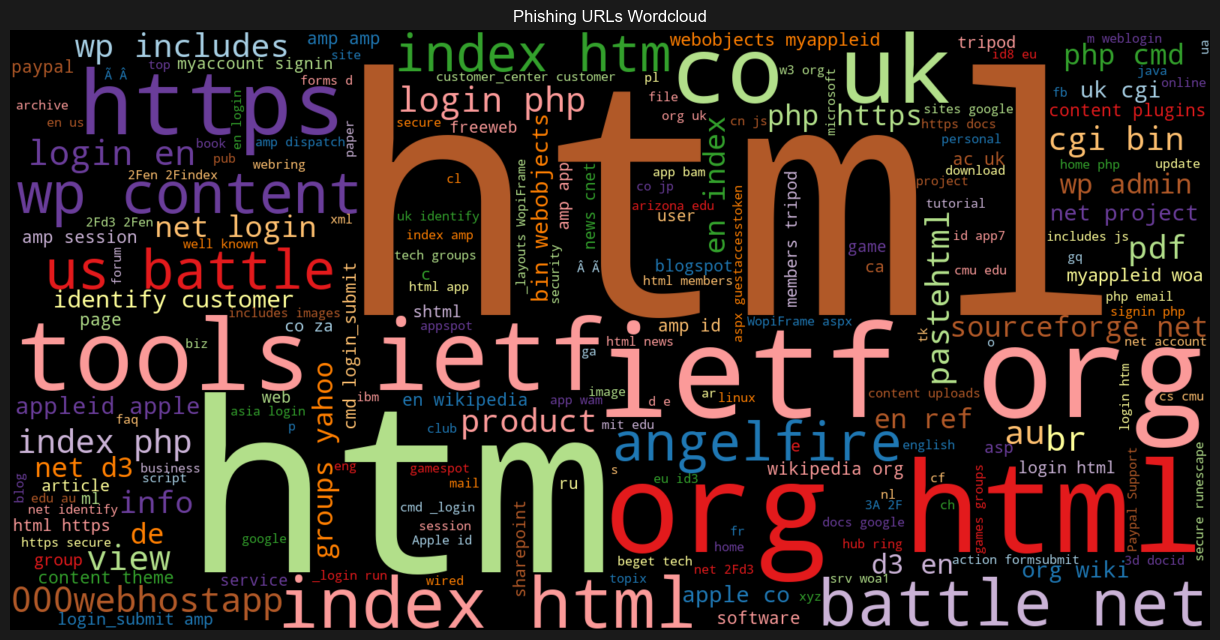

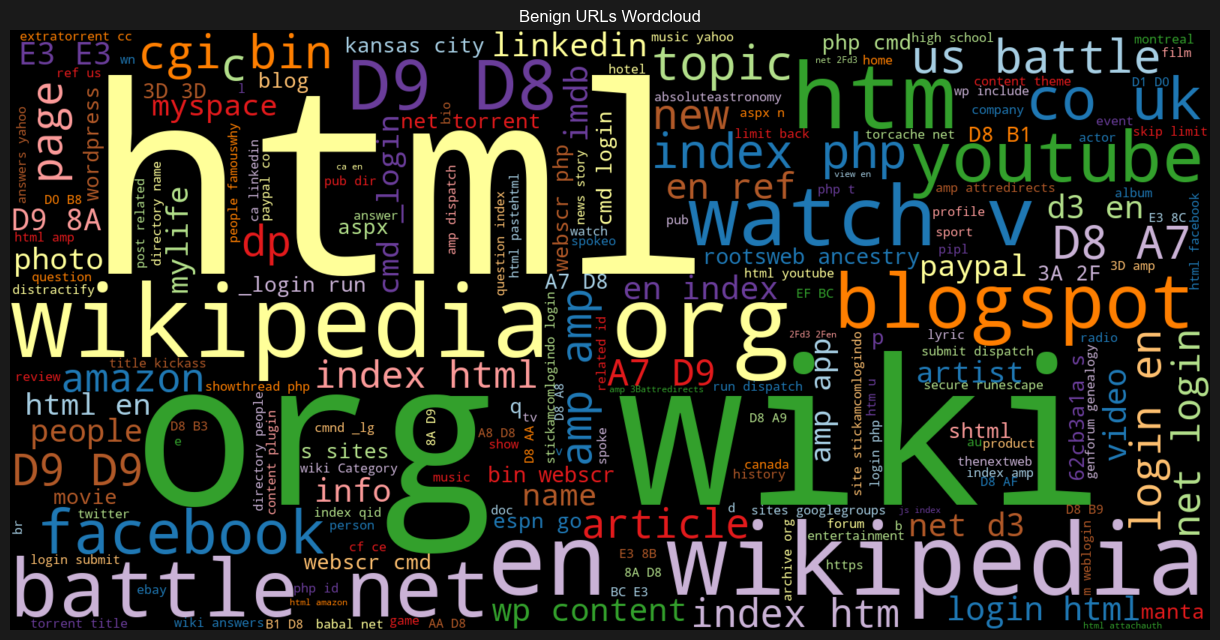

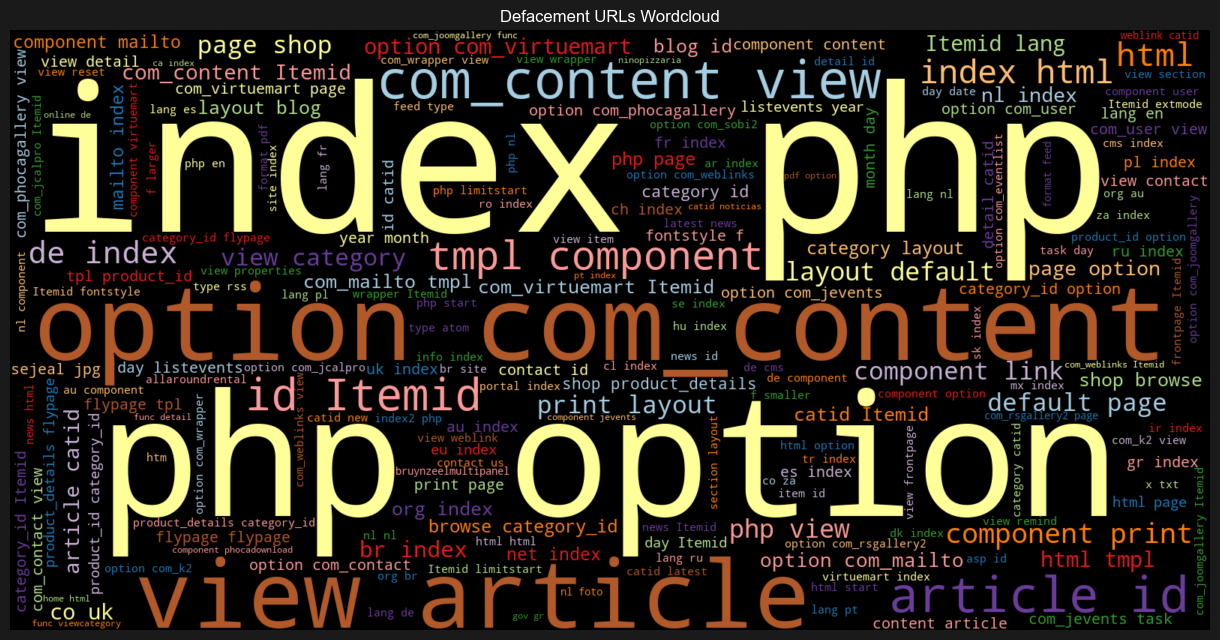

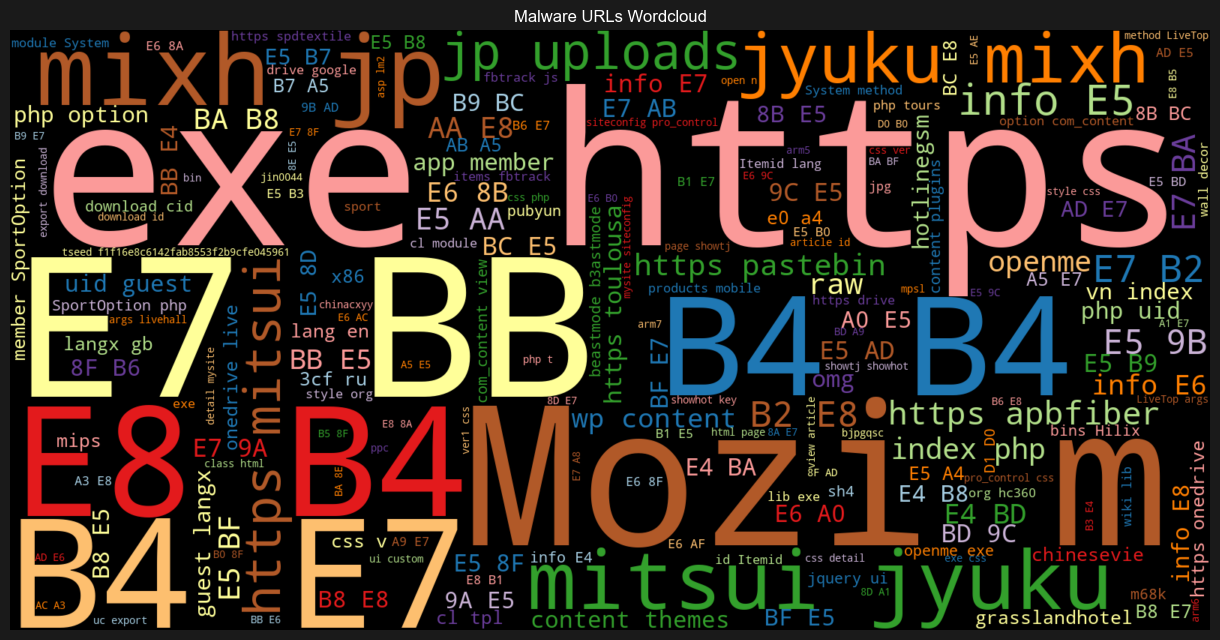

In [8]:
def plot_wordcloud(data_subset, title):
    """Plot a word cloud for a given subset of data."""
    combined_urls = " ".join(i for i in data_subset.url if isinstance(i, str))
    wordcloud = WordCloud(width=1600, height=800, colormap='Paired', background_color='black').generate(combined_urls)
    plt.figure(figsize=(12, 14), facecolor='k')
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(title, color='white')
    plt.tight_layout(pad=0)
    plt.show()

# Plot wordclouds for each class
classes = data['type'].unique()
for cls in classes:
    subset = data[data.type == cls]
    plot_wordcloud(subset, f"{cls.capitalize()} URLs Wordcloud")

# *This will display word clouds for each class (`benign`, `malicious`, etc.), highlighting the most frequent words in the URLs.*

# ======================================
# 7. Feature Engineering
# ======================================

Apply the previously defined feature engineering functions to extract features from the URLs.

In [9]:
print("\nStarting feature engineering...")

# Apply feature engineering functions
data['secure_http'] = data['url'].apply(secure_http)
data['url_length'] = data['url'].apply(url_length)
data['find_subdomain'] = data['url'].apply(find_subdomain)
data['tld'] = data['url'].apply(get_tld_func)
data['domain_token_count'] = data['url'].apply(domain_token_count)
data['hostname_length'] = data['url'].apply(hostname_length)
data['root_domain'] = data['url'].apply(extract_root_domain)
data['count.'] = data['url'].apply(count_dot)
data['count_dir'] = data['url'].apply(no_of_dir)
data['count%'] = data['url'].apply(lambda x: x.count('%') if isinstance(x, str) else 0)
data['count?'] = data['url'].apply(lambda x: x.count('?') if isinstance(x, str) else 0)
data['count-'] = data['url'].apply(lambda x: x.count('-') if isinstance(x, str) else 0)
data['count='] = data['url'].apply(lambda x: x.count('=') if isinstance(x, str) else 0)
data['count-digits'] = data['url'].apply(digit_count)
data['count-letters'] = data['url'].apply(letter_count)
data['fd_length'] = data['url'].apply(fd_length)
data['path_length'] = data['url'].apply(path_length)
data['NumQueryComponents'] = data['url'].apply(num_query_components)
data['short_url'] = data['url'].apply(shortening_service)
data['abnormal_url'] = data['url'].apply(abnormal_url)
data['sus_url'] = data['url'].apply(suspicious_words)
data['use_of_ip'] = data['url'].apply(having_ip_address)
data['contains_file'] = data['url'].apply(contains_file)

# Terapkan fitur is_trusted_tld dengan parameter weight dan https_bonus yang lebih tinggi
data['is_trusted_tld'] = data['url'].apply(lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Tambahkan fitur kombinasi
data['trusted_and_https'] = data['is_trusted_tld'] * data['secure_http']

# Pilih Feature Columns, tambahkan 'trusted_and_https' jika Anda menggunakan fitur ini
feature_columns = [
    'secure_http', 'url_length', 'find_subdomain', 'tld', 'domain_token_count',
    'hostname_length', 'root_domain', 'count.', 'count_dir', 'count%', 'count?',
    'count-', 'count=', 'count-digits', 'count-letters', 'fd_length',
    'path_length', 'NumQueryComponents', 'short_url', 'abnormal_url',
    'sus_url', 'use_of_ip', 'contains_file', 'is_trusted_tld', 
    'trusted_and_https'
]

# ======================================
# 8. Feature Selection
# ======================================

# Select the relevant features for model training
X = data[feature_columns]
y = data['type']

print("\nFeature matrix X shape:", X.shape)
print("Target vector y distribution:")
print(y.value_counts())


Starting feature engineering...

Feature matrix X shape: (652528, 25)
Target vector y distribution:
type
benign        429440
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64


# ======================================
# 9. Label Encoding
# ======================================

Encode the target labels into numerical values suitable for model training.

In [10]:
print("\nEncoding target labels...")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes found and their corresponding encoded labels:")
for idx, class_label in enumerate(label_encoder.classes_):
    print(f"{class_label}: {idx}")

# Save the label encoder for future use
dump(label_encoder, LABEL_ENCODER_PATH)
print(f"Label encoder saved to {LABEL_ENCODER_PATH}")


Encoding target labels...
Classes found and their corresponding encoded labels:
benign: 0
defacement: 1
malware: 2
phishing: 3
Label encoder saved to label_encoder.pkl


# ======================================
# 10. Handling Missing Values for Categorical Features
# ======================================

Mengisi nilai null di fitur kategorikal sebelum melakukan encoding.

In [11]:
# Mengisi nilai null di fitur kategorikal yang akan di-encode
X[['find_subdomain', 'tld', 'root_domain']] = X[['find_subdomain', 'tld', 'root_domain']].fillna('missing')

# Verifikasi tidak ada nilai null di kolom kategorikal
print("\nNull values after filling:")
print(X[['find_subdomain', 'tld', 'root_domain']].isnull().sum())


Null values after filling:
find_subdomain    0
tld               0
root_domain       0
dtype: int64


/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_40400/1592181067.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['find_subdomain', 'tld', 'root_domain']] = X[['find_subdomain', 'tld', 'root_domain']].fillna('missing')


# ======================================
# 11. Encoding Categorical Features with TargetEncoder
# ======================================

Gunakan `TargetEncoder` untuk meng-encode fitur kategorikal.

In [12]:
from category_encoders import TargetEncoder

# Initialize the TargetEncoder dengan kolom yang akan di-encode
encoder = TargetEncoder(cols=['find_subdomain', 'tld', 'root_domain'])

# Fit encoder pada data training
encoder.fit(X, y_encoded)

# Transform data training
X_encoded = encoder.transform(X)

print("\nFeature engineering completed. Here's a preview:")
print(X_encoded.head())

# Save the encoder for future use
dump(encoder, ENCODER_PATH)
print(f"Target encoder saved to {ENCODER_PATH}")


Feature engineering completed. Here's a preview:
   secure_http  url_length  find_subdomain       tld  domain_token_count  \
0            0          16        0.420859  1.066080                   3   
1            0          35        0.420859  0.496081                   2   
2            0          31        0.420859  0.637739                   2   
3            0          81        1.478495  1.186736                   3   
4            0         228        0.420859  0.727536                   2   

   hostname_length   root_domain  count.  count_dir  count%  ...  fd_length  \
0               16  9.819996e-01       2          0       0  ...          0   
1               11  2.096854e-10       2          2       0  ...          5   
2               14  5.916742e-01       2          3       0  ...          7   
3               21  9.651076e-01       3          1       0  ...          9   
4               23  9.999122e-01       2          1       0  ...          9   

   path_length  Nu

# ======================================
# 12. Cross-Validation with XGBoost
# ======================================

Perform k-fold cross-validation to evaluate the model's performance across different subsets of the data.


Starting cross-validation with XGBoost classifier...

--- Fold 1 ---
Class distribution before oversampling:
0    375928
1     84266
3     82279
2     28489
Name: count, dtype: int64
Class distribution after oversampling:
3    375928
0    375928
1    375928
2    375928
Name: count, dtype: int64


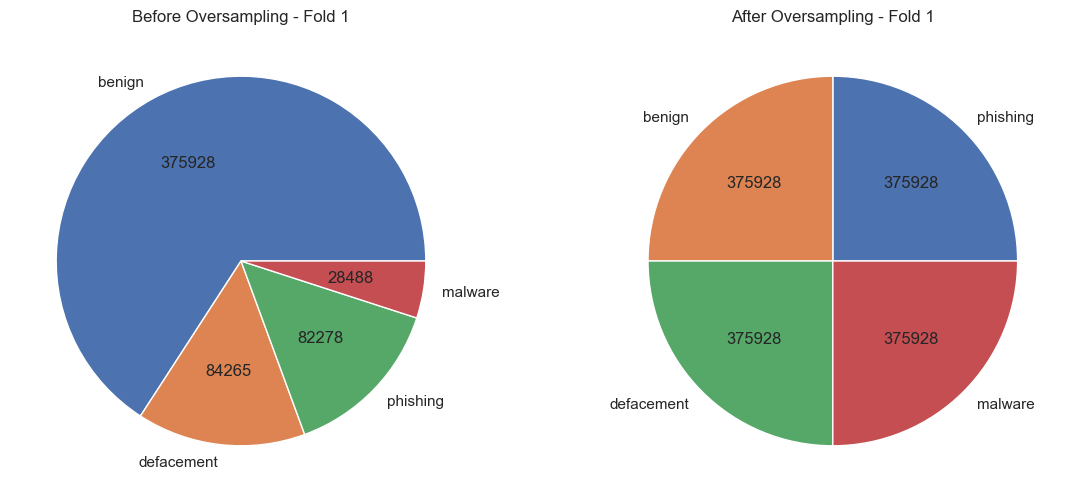

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:56:43] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53512
  defacement       0.99      1.00      0.99     12191
     malware       0.97      0.99      0.98      4031
    phishing       0.95      0.97      0.96     11832

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


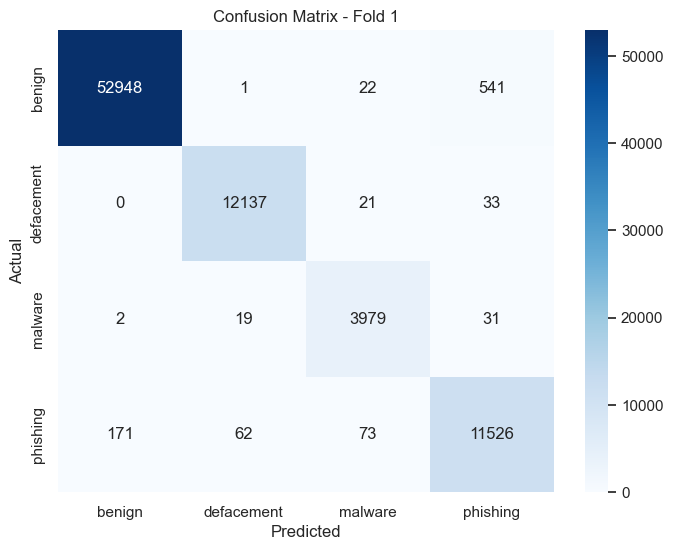

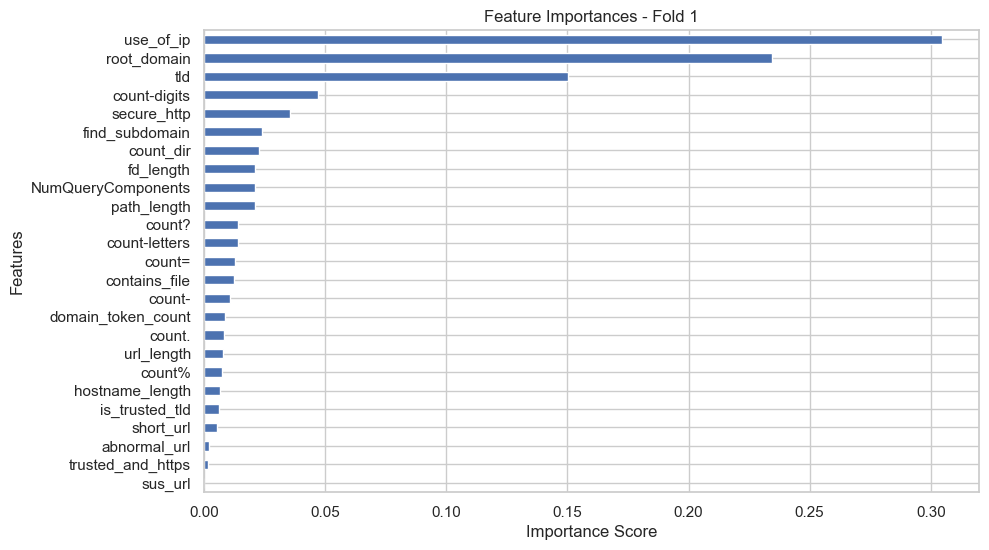


--- Fold 2 ---
Class distribution before oversampling:
0    375637
1     84536
3     82271
2     28518
Name: count, dtype: int64
Class distribution after oversampling:
0    375637
1    375637
3    375637
2    375637
Name: count, dtype: int64


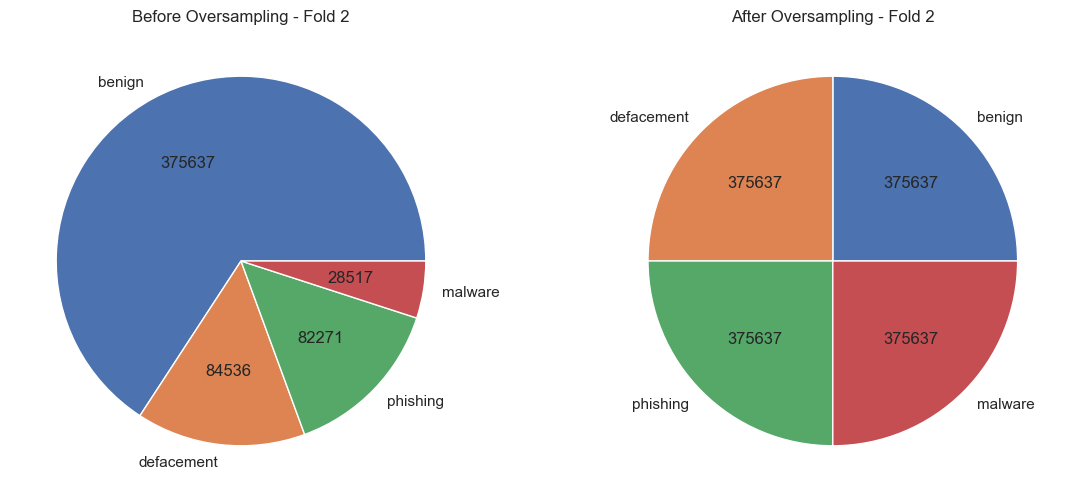

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:57:08] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53803
  defacement       0.99      1.00      0.99     11921
     malware       0.97      0.98      0.98      4002
    phishing       0.95      0.97      0.96     11840

    accuracy                           0.99     81566
   macro avg       0.98      0.98      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


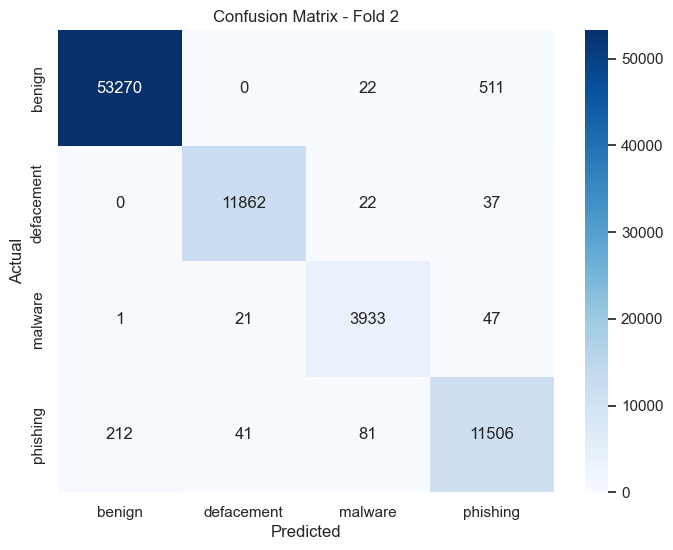

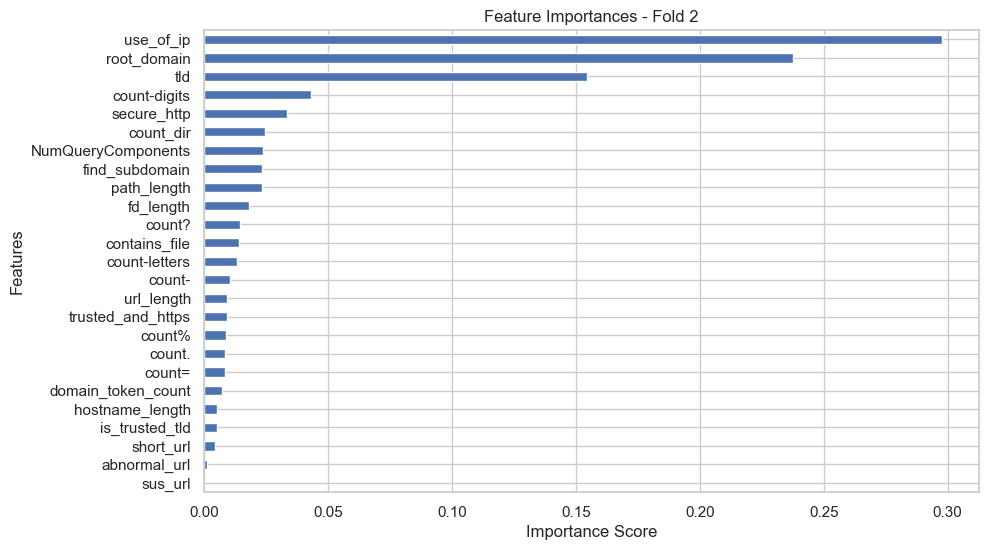


--- Fold 3 ---
Class distribution before oversampling:
0    375541
1     84546
3     82453
2     28422
Name: count, dtype: int64
Class distribution after oversampling:
3    375541
0    375541
1    375541
2    375541
Name: count, dtype: int64


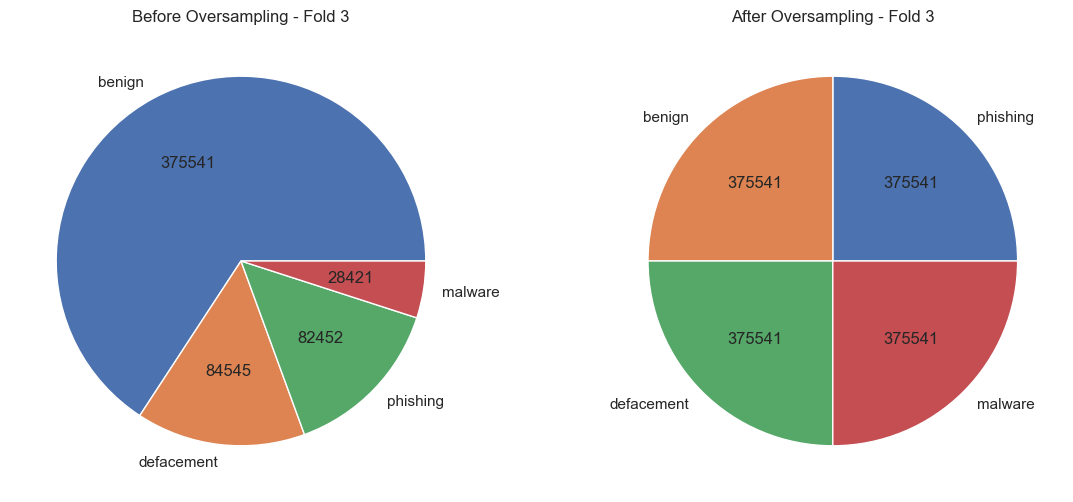

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:57:31] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53899
  defacement       1.00      1.00      1.00     11911
     malware       0.97      0.99      0.98      4098
    phishing       0.95      0.98      0.96     11658

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


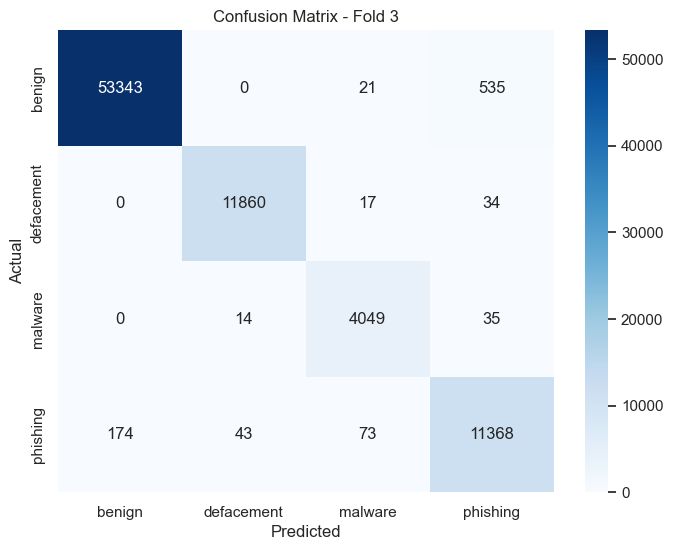

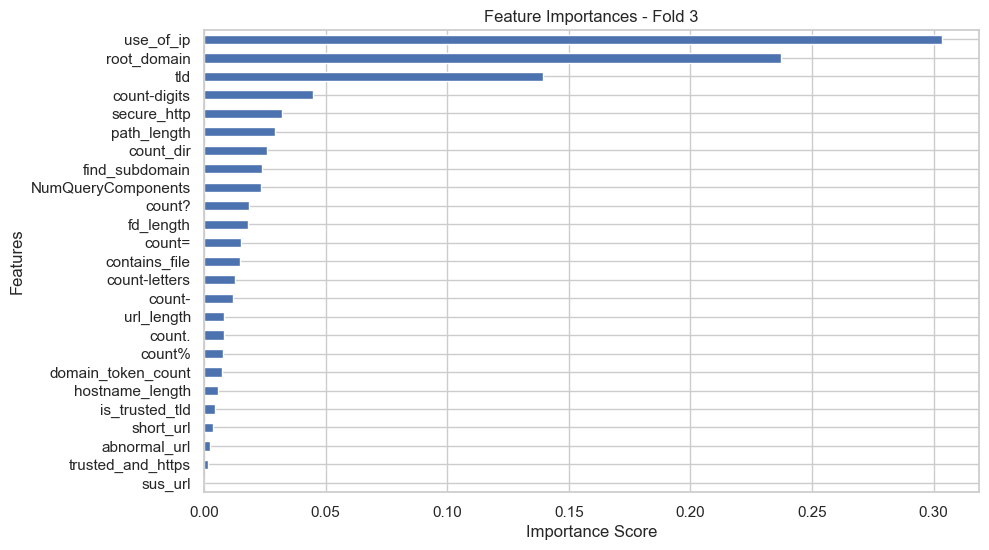


--- Fold 4 ---
Class distribution before oversampling:
0    375605
1     84453
3     82419
2     28485
Name: count, dtype: int64
Class distribution after oversampling:
3    375605
0    375605
1    375605
2    375605
Name: count, dtype: int64


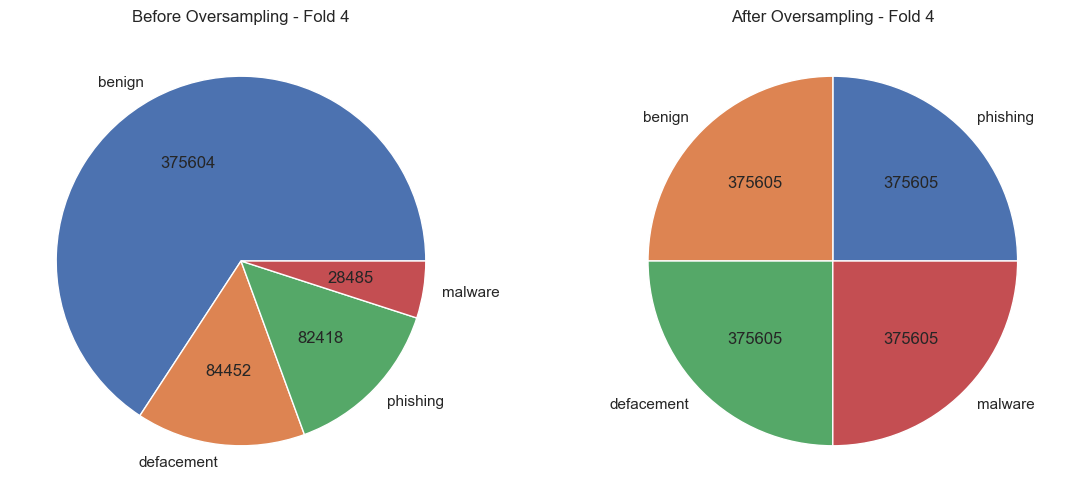

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:57:55] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53835
  defacement       0.99      1.00      0.99     12004
     malware       0.97      0.99      0.98      4035
    phishing       0.95      0.97      0.96     11692

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


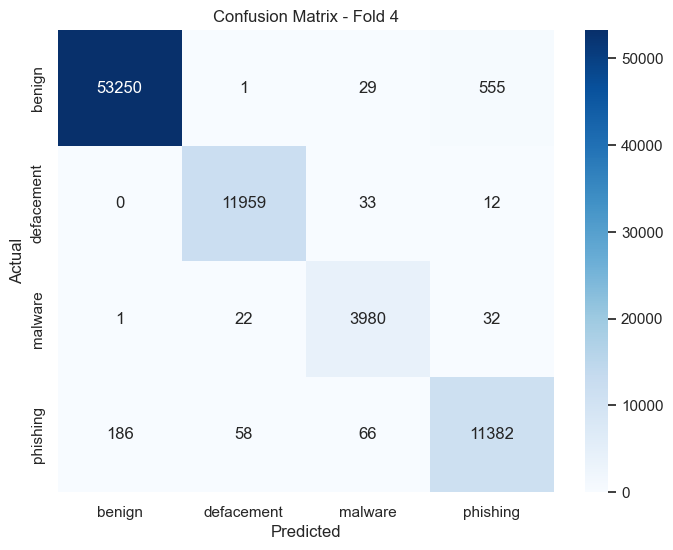

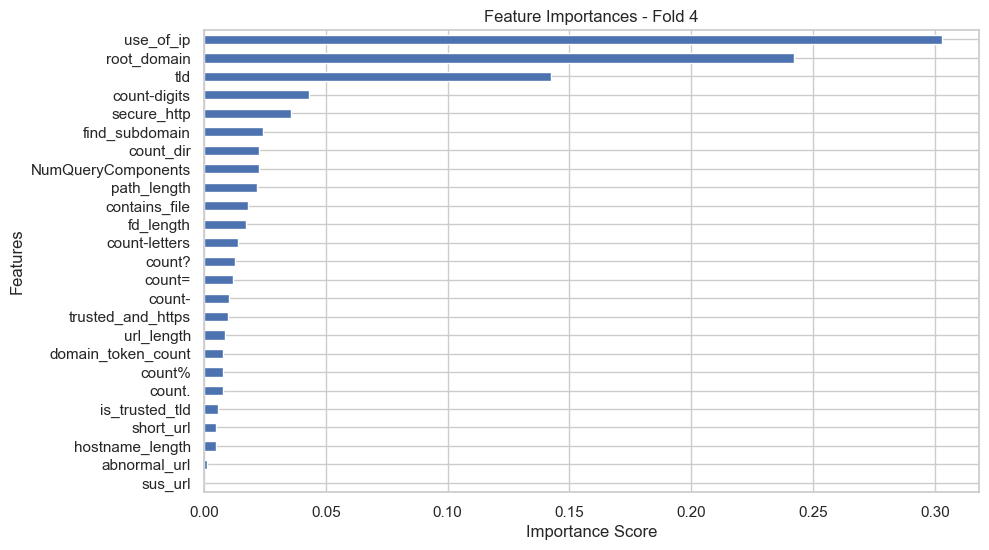


--- Fold 5 ---
Class distribution before oversampling:
0    376078
1     84090
3     82317
2     28477
Name: count, dtype: int64
Class distribution after oversampling:
3    376078
0    376078
1    376078
2    376078
Name: count, dtype: int64


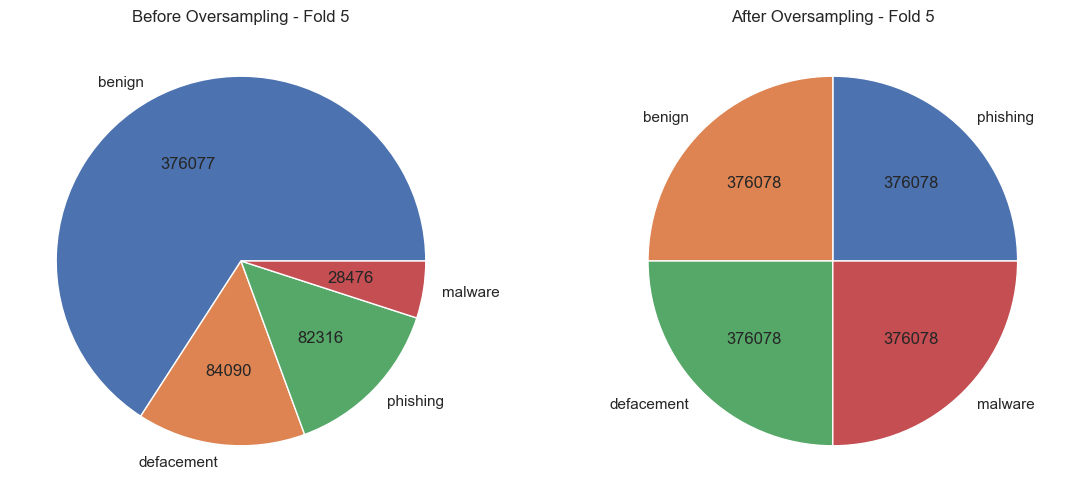

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:58:16] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53362
  defacement       0.99      0.99      0.99     12367
     malware       0.97      0.98      0.98      4043
    phishing       0.95      0.97      0.96     11794

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


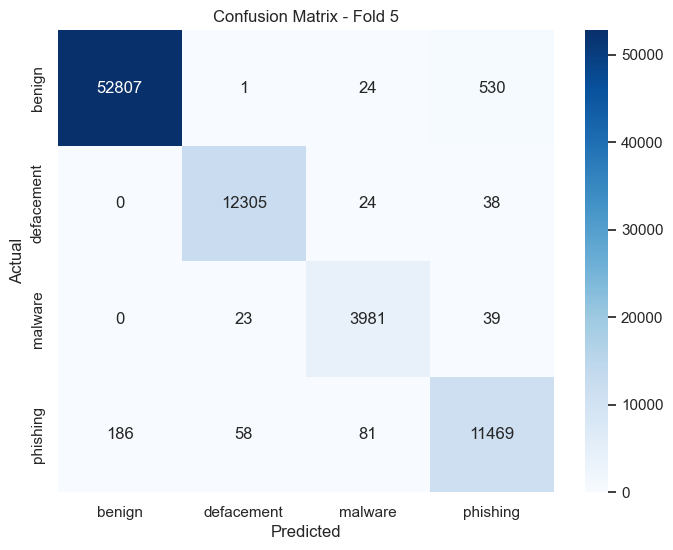

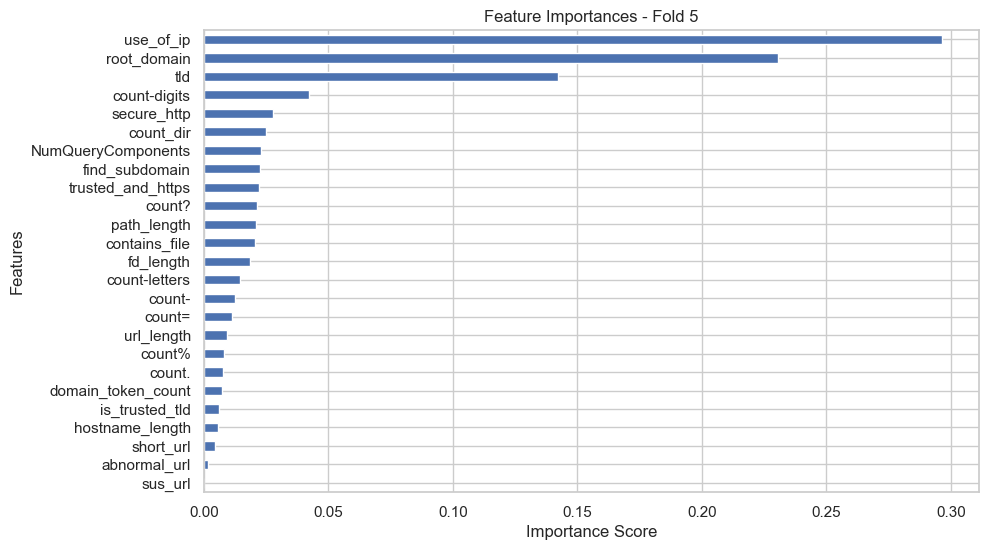


--- Fold 6 ---
Class distribution before oversampling:
0    375798
1     84428
3     82267
2     28469
Name: count, dtype: int64
Class distribution after oversampling:
3    375798
0    375798
1    375798
2    375798
Name: count, dtype: int64


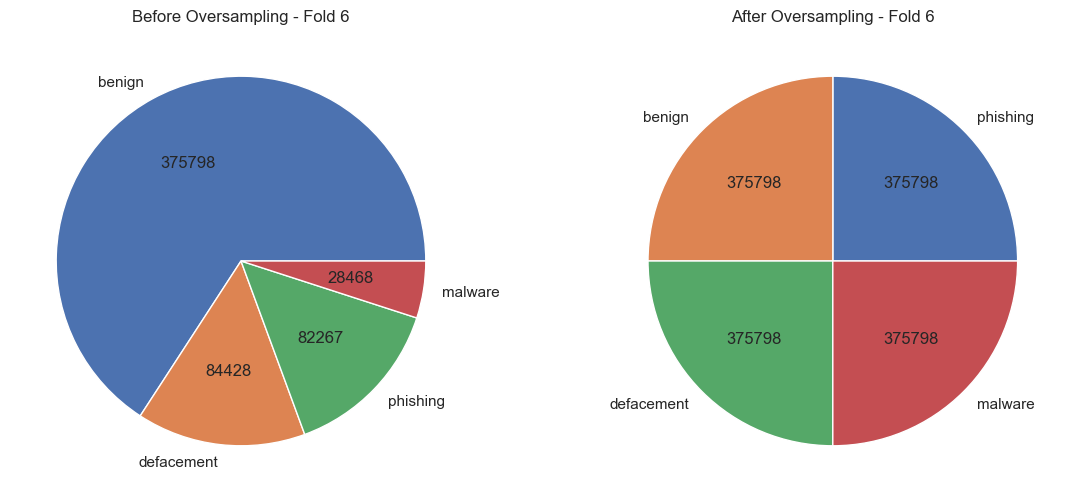

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:58:37] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53642
  defacement       0.99      1.00      0.99     12029
     malware       0.97      0.98      0.98      4051
    phishing       0.95      0.97      0.96     11844

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


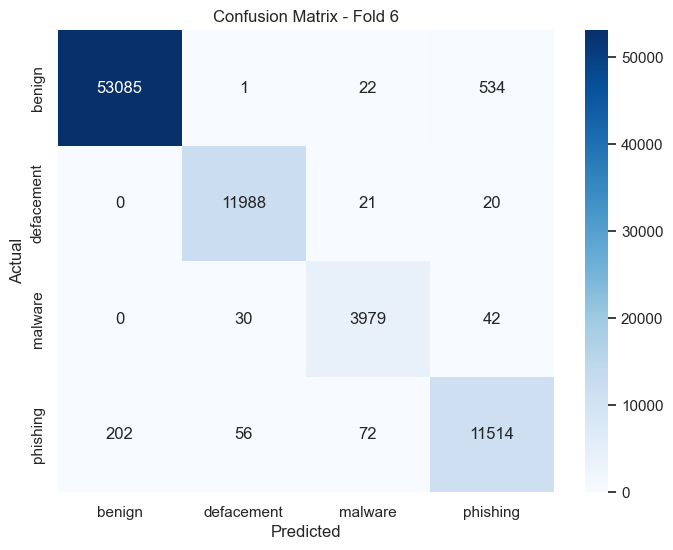

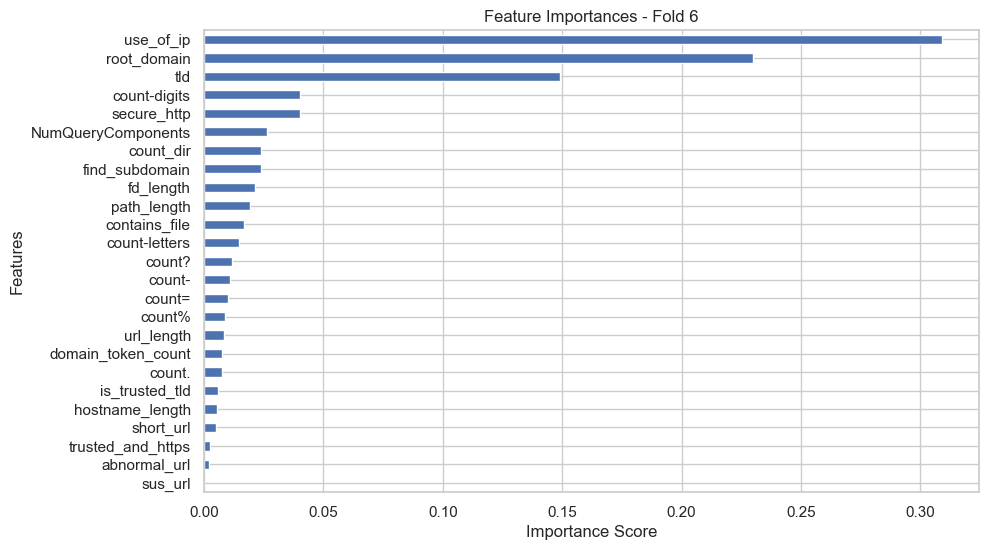


--- Fold 7 ---
Class distribution before oversampling:
0    375638
1     84431
3     82457
2     28436
Name: count, dtype: int64
Class distribution after oversampling:
3    375638
0    375638
1    375638
2    375638
Name: count, dtype: int64


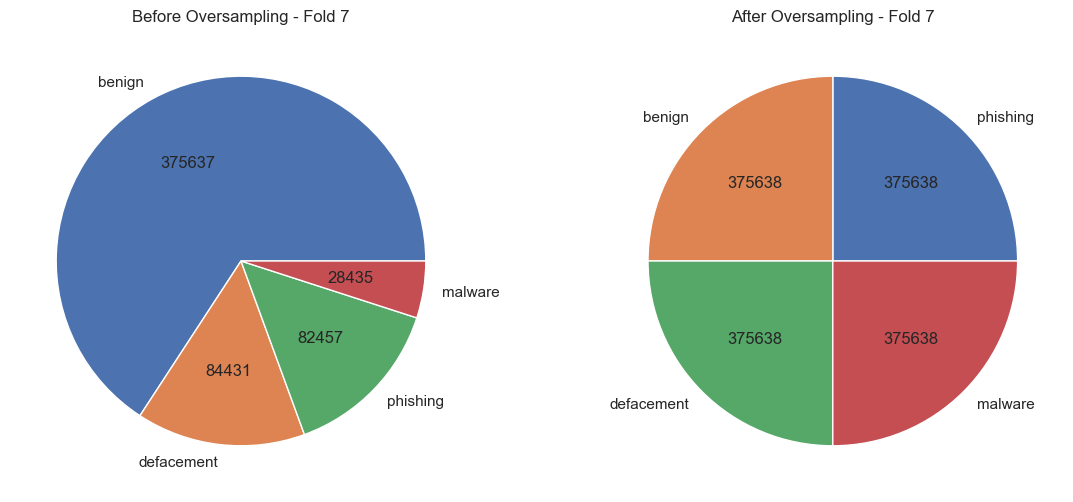

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:58:58] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53802
  defacement       0.99      1.00      0.99     12026
     malware       0.98      0.99      0.98      4084
    phishing       0.95      0.97      0.96     11654

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


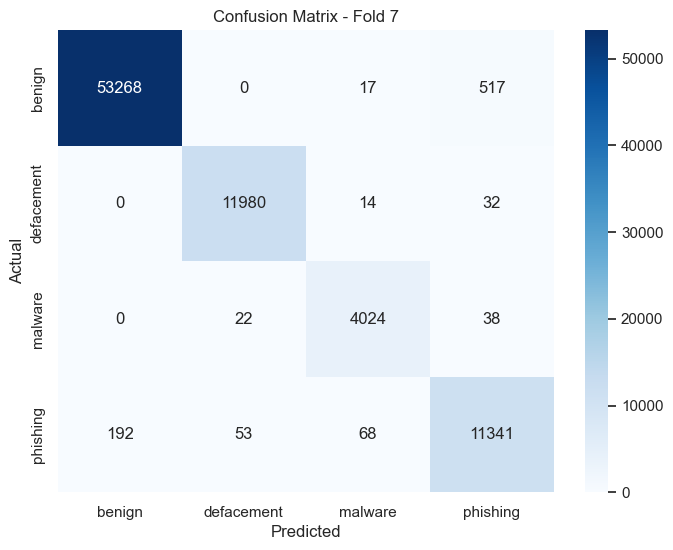

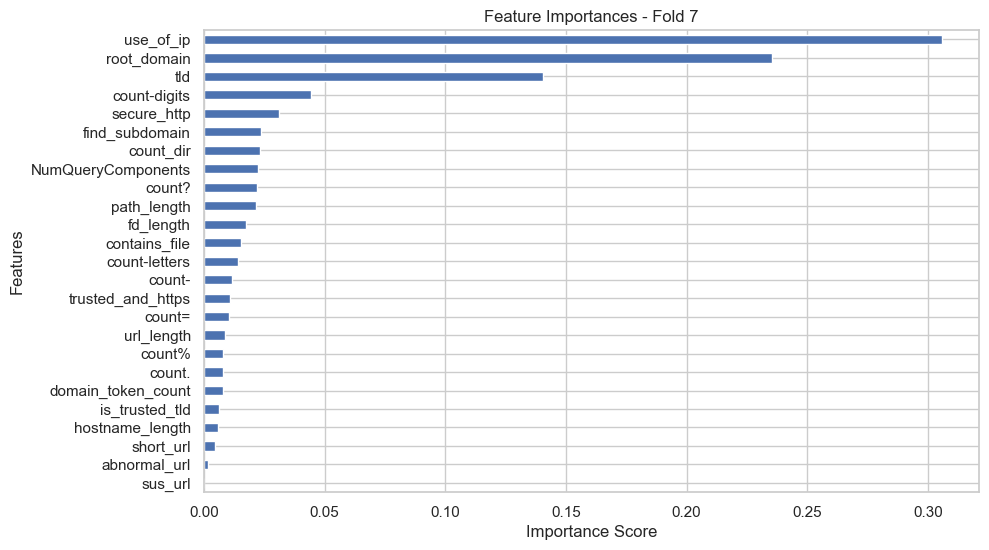


--- Fold 8 ---
Class distribution before oversampling:
0    375855
1     84449
3     82314
2     28344
Name: count, dtype: int64
Class distribution after oversampling:
3    375855
0    375855
1    375855
2    375855
Name: count, dtype: int64


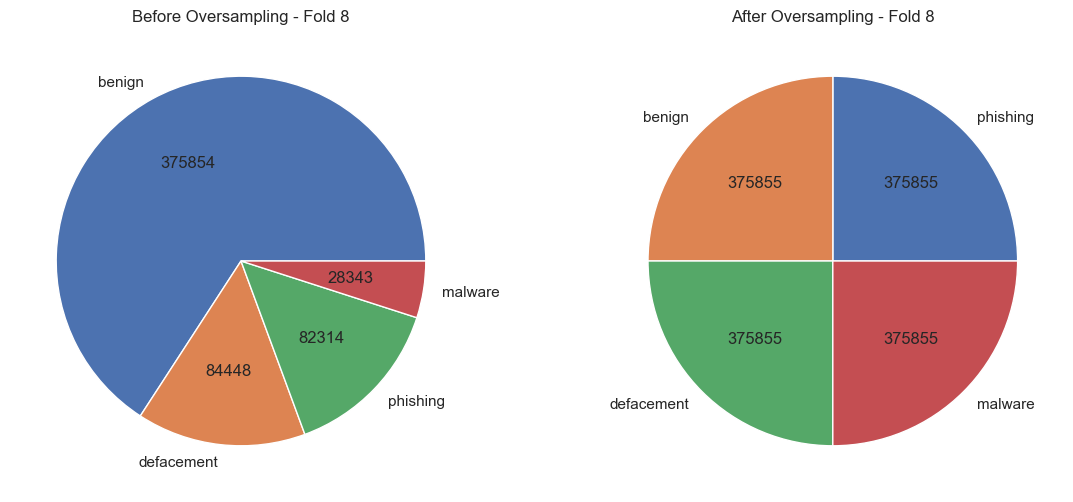

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:59:19] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Classification Report:
              precision    recall  f1-score   support

      benign       1.00      0.99      0.99     53585
  defacement       0.99      1.00      0.99     12008
     malware       0.98      0.99      0.98      4176
    phishing       0.95      0.97      0.96     11797

    accuracy                           0.99     81566
   macro avg       0.98      0.99      0.98     81566
weighted avg       0.99      0.99      0.99     81566

Accuracy: 0.988


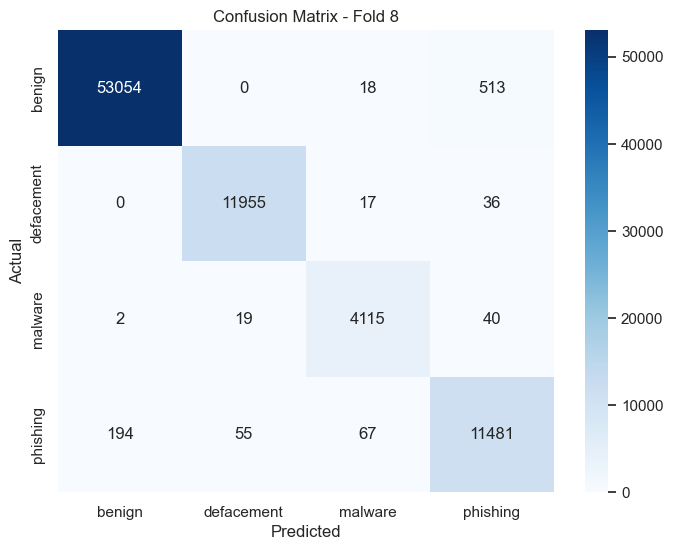

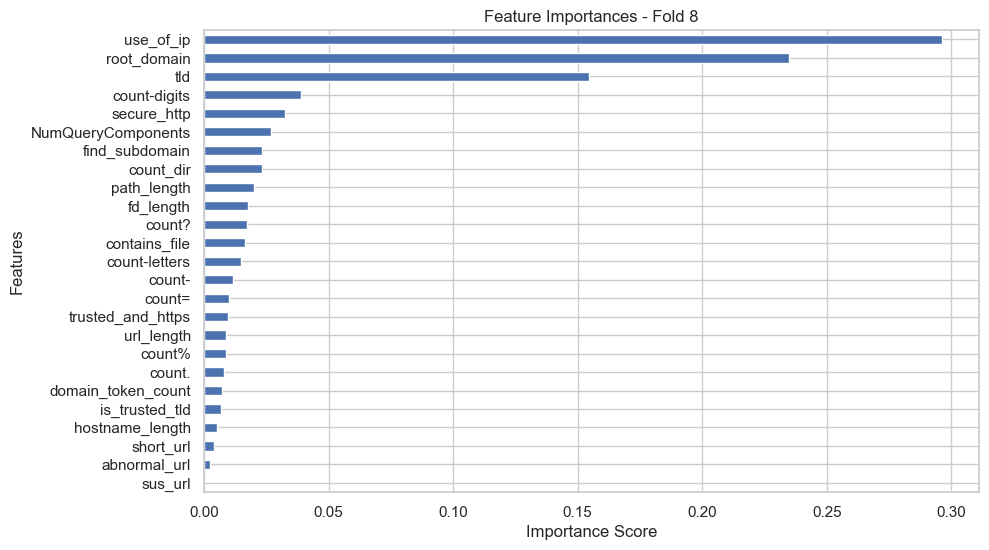

In [13]:
print("\nStarting cross-validation with XGBoost classifier...")

# Initialize k-fold cross-validator
num_folds = 8
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

# Lists to store metrics
accuracy_scores = []
confusion_matrices = []
feature_importances_list = []

fold_number = 1

for train_index, test_index in kf.split(X_encoded, y_encoded):
    print(f"\n--- Fold {fold_number} ---")

    X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
    y_train_fold, y_test_fold = y_encoded[train_index], y_encoded[test_index]

    # Initialize RandomOverSampler
    ros = RandomOverSampler(sampling_strategy="not majority", random_state=42)
    X_train_ros, y_train_ros = ros.fit_resample(X_train_fold, y_train_fold)

    # Store class distributions
    class_distribution_before = pd.Series(y_train_fold).value_counts()
    class_distribution_after = pd.Series(y_train_ros).value_counts()
    print("Class distribution before oversampling:")
    print(class_distribution_before)
    print("Class distribution after oversampling:")
    print(class_distribution_after)

    # Plot class distribution before and after oversampling
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # Before Oversampling
    labels_before = label_encoder.inverse_transform(class_distribution_before.index)
    ax1.pie(class_distribution_before, labels=labels_before, autopct=lambda p: f'{int(p * class_distribution_before.sum() / 100)}')
    ax1.set_title(f"Before Oversampling - Fold {fold_number}")

    # After Oversampling
    labels_after = label_encoder.inverse_transform(class_distribution_after.index)
    ax2.pie(class_distribution_after, labels=labels_after, autopct=lambda p: f'{int(p * class_distribution_after.sum() / 100)}')
    ax2.set_title(f"After Oversampling - Fold {fold_number}")

    plt.show()

    # Initialize XGBoost Classifier tanpa use_label_encoder
    xgb_model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        eval_metric='mlogloss',  # Pastikan eval_metric sesuai dengan kebutuhan
        use_label_encoder=False,
        n_jobs=-1
    )

    # Train the model
    xgb_model.fit(X_train_ros, y_train_ros)

    # Predict on test fold
    y_pred_xgb = xgb_model.predict(X_test_fold)

    # Confusion Matrix
    cm_fold = metrics.confusion_matrix(y_test_fold, y_pred_xgb, labels=np.arange(len(label_encoder.classes_)))
    confusion_matrices.append(cm_fold)

    # Classification Report
    print("\nClassification Report:")
    print(metrics.classification_report(y_test_fold, y_pred_xgb, target_names=label_encoder.classes_))

    # Accuracy Score
    score = metrics.accuracy_score(y_test_fold, y_pred_xgb)
    print(f"Accuracy: {score:.3f}")
    accuracy_scores.append(score)

    # Confusion Matrix Heatmap
    cm_df_fold = pd.DataFrame(cm_fold, index=label_encoder.classes_,
                              columns=label_encoder.classes_)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df_fold, annot=True, fmt="d", cmap='Blues')
    plt.title(f'Confusion Matrix - Fold {fold_number}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # Feature Importances
    feat_importances = pd.Series(xgb_model.feature_importances_, index=X_train_ros.columns)
    feat_importances.sort_values(ascending=True).plot(kind="barh", figsize=(10, 6))
    plt.title(f'Feature Importances - Fold {fold_number}')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

    # Store feature importances
    feature_importances_list.append(feat_importances)

    fold_number += 1

# ======================================
# 13. Summary of Cross-Validation Metrics
# ======================================

Calculate and visualize the average accuracy and feature importances across all folds.


Average Accuracy Across 8 Folds: 0.988


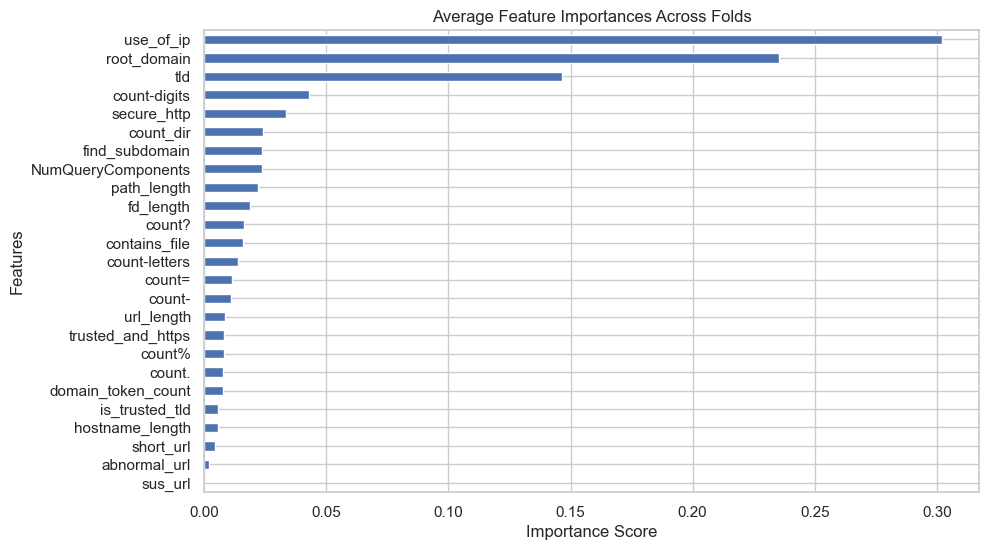

In [14]:
# Average Accuracy
average_accuracy = np.mean(accuracy_scores)
print(f"\nAverage Accuracy Across {num_folds} Folds: {average_accuracy:.3f}")

# Aggregate Feature Importances
average_feature_importances = pd.concat(feature_importances_list, axis=1).mean(axis=1).sort_values()
average_feature_importances.plot(kind="barh", figsize=(10, 6))
plt.title('Average Feature Importances Across Folds')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# ======================================
# 14. Training the Final Model
# ======================================

Train the final XGBoost model on the entire dataset after balancing it with oversampling.


Training final model on the entire dataset...

Class Distribution After Oversampling:
3    429440
0    429440
1    429440
2    429440
Name: count, dtype: int64
Classes:
['phishing' 'benign' 'defacement' 'malware']


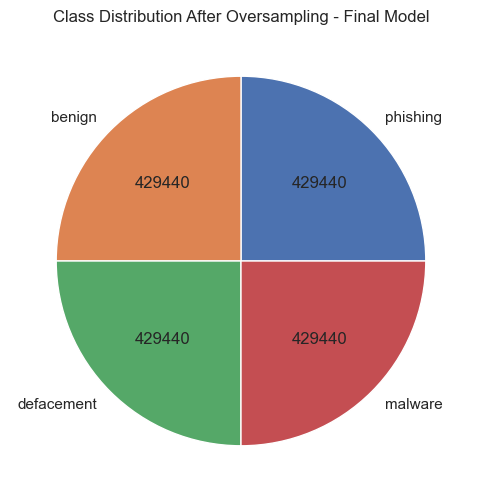

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/xgboost/core.py:158: UserWarning: [21:59:40] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


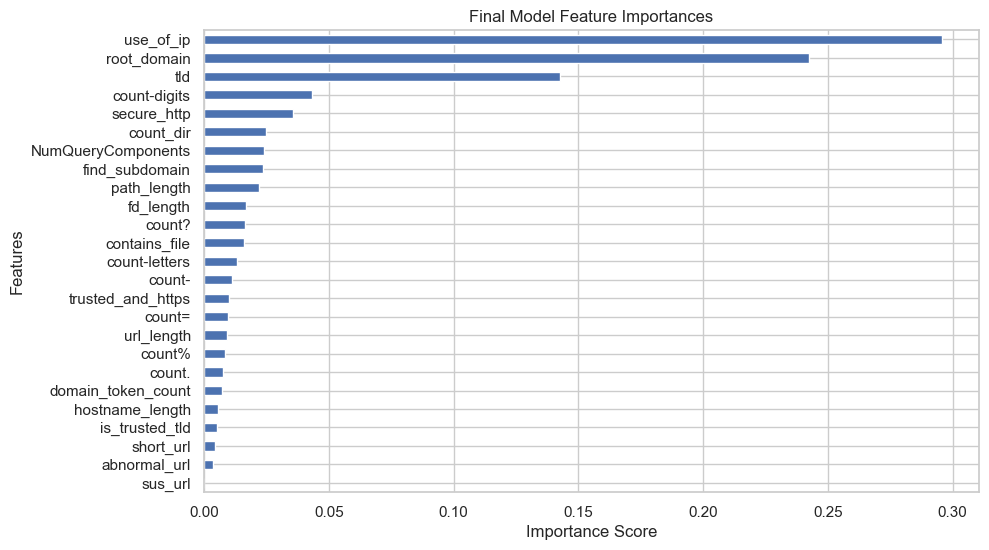

Final XGBoost model saved to final_xgb_model.pkl


In [15]:
print("\nTraining final model on the entire dataset...")

# Initialize RandomOverSampler for the entire dataset
ros_final = RandomOverSampler(sampling_strategy="not majority", random_state=42)
X_resampled, y_resampled = ros_final.fit_resample(X_encoded, y_encoded)

print("\nClass Distribution After Oversampling:")
class_dist_final = pd.Series(y_resampled).value_counts()
print(class_dist_final)
print("Classes:")
print(label_encoder.inverse_transform(class_dist_final.index))

# Plot final class distribution
plt.figure(figsize=(6,6))
labels_final = label_encoder.inverse_transform(class_dist_final.index)
plt.pie(class_dist_final, labels=labels_final, autopct=lambda p: f'{int(p * class_dist_final.sum() / 100)}')
plt.title("Class Distribution After Oversampling - Final Model")
plt.show()

# Initialize XGBoost Classifier
final_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss',
    use_label_encoder=False,
    n_jobs=-1
)

# Train the final model
final_xgb.fit(X_resampled, y_resampled)

# Feature Importances for Final Model
feat_importances_final = pd.Series(final_xgb.feature_importances_, index=X_resampled.columns)
feat_importances_final.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title('Final Model Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Save the final model
dump(final_xgb, MODEL_PATH)
print(f"Final XGBoost model saved to {MODEL_PATH}")

# ======================================
# 15. Predicting on Test URLs
# ======================================

Prepare a set of test URLs, apply feature engineering, and use the trained model to predict their classifications.

In [18]:
from IPython.display import display
import joblib

print("\nPreparing test URLs for prediction...")

# Daftar URL untuk pengujian (pastikan koma yang hilang telah ditambahkan)
test_urls = [
    'https://www.google.com/info', 'https://www.facebook.com', 'https://www.amazon.com', 'https://www.netflix.com',
    'https://www.reddit.com', 'https://www.youtube.com/', 'https://www.twitter.com', 'https://www.linkedin.com',
    'https://www.instagram.com', 'https://www.microsoft.com', 'https://www.apple.com', 'https://www.github.com',
    'https://www.wikipedia.org', 'https://www.quora.com', 'https://www.pinterest.com', 'https://www.ebay.com',
    'https://www.dropbox.com', 'https://www.paypal.com', 'https://www.salesforce.com', 'https://www.tesla.com',
    "allmusic.com/album/crazy-from-the-heat-r16990", 
    "http://peluqueriadeautor.com/index.php?option=com_virtuemart&page=shop.browse&category_id=31&Itemid=70", 
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD", 
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD", 
    "http://alexpay2.beget.tech", 
    'http://www.pn-wuppertal.de/links/2-linkseite/5-httpwwwkrebshilfede',
    "https://spada.upnyk.ac.id/login/index.php", 
    "https://bima.upnyk.ac.id/"
]

# Konversi URL ke dalam DataFrame
test_data = pd.DataFrame({'url': test_urls})

# Apply feature engineering functions
test_data['secure_http'] = test_data['url'].apply(secure_http)
test_data['url_length'] = test_data['url'].apply(url_length)
test_data['find_subdomain'] = test_data['url'].apply(find_subdomain)
test_data['tld'] = test_data['url'].apply(get_tld_func)
test_data['domain_token_count'] = test_data['url'].apply(domain_token_count)
test_data['hostname_length'] = test_data['url'].apply(hostname_length)
test_data['root_domain'] = test_data['url'].apply(extract_root_domain)
test_data['count.'] = test_data['url'].apply(count_dot)
test_data['count_dir'] = test_data['url'].apply(no_of_dir)
test_data['count%'] = test_data['url'].apply(lambda x: x.count('%') if isinstance(x, str) else 0)
test_data['count?'] = test_data['url'].apply(lambda x: x.count('?') if isinstance(x, str) else 0)
test_data['count-'] = test_data['url'].apply(lambda x: x.count('-') if isinstance(x, str) else 0)
test_data['count='] = test_data['url'].apply(lambda x: x.count('=') if isinstance(x, str) else 0)
test_data['count-digits'] = test_data['url'].apply(digit_count)
test_data['count-letters'] = test_data['url'].apply(letter_count)
test_data['fd_length'] = test_data['url'].apply(fd_length)
test_data['path_length'] = test_data['url'].apply(path_length)
test_data['NumQueryComponents'] = test_data['url'].apply(num_query_components)
test_data['short_url'] = test_data['url'].apply(shortening_service)
test_data['abnormal_url'] = test_data['url'].apply(abnormal_url)
test_data['sus_url'] = test_data['url'].apply(suspicious_words)
test_data['use_of_ip'] = test_data['url'].apply(having_ip_address)
test_data['contains_file'] = test_data['url'].apply(contains_file)

# Terapkan fitur is_trusted_tld dengan parameter weight dan https_bonus yang lebih tinggi
test_data['is_trusted_tld'] = test_data['url'].apply(lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Tambahkan fitur kombinasi
test_data['trusted_and_https'] = test_data['is_trusted_tld'] * test_data['secure_http']

# Pilih Feature Columns
test_features = test_data[feature_columns]

# Mengisi nilai null di fitur kategorikal yang akan di-encode
test_features[['find_subdomain', 'tld', 'root_domain']] = test_features[['find_subdomain', 'tld', 'root_domain']].fillna('missing')

# Load the TargetEncoder and LabelEncoder
try:
    encoder_loaded = load(ENCODER_PATH)
    label_encoder_loaded = load(LABEL_ENCODER_PATH)
    final_xgb_loaded = load(MODEL_PATH)
    print(f"Encoders and model loaded successfully from {ENCODER_PATH}, {LABEL_ENCODER_PATH}, and {MODEL_PATH}.")
except FileNotFoundError as e:
    print(f"Error: {e}. Ensure that the encoder and model files exist.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading encoders and model: {e}")
    exit(1)

# Transform test_data using the loaded encoder
X_test_encoded = encoder_loaded.transform(test_features)

print("\nFeature engineering on test data completed. Here's a preview:")
print(X_test_encoded.head())

# Predict using the loaded model
test_predictions_encoded = final_xgb_loaded.predict(X_test_encoded)

# Decode the predictions to original labels
test_predictions = label_encoder_loaded.inverse_transform(test_predictions_encoded)

# Tampilkan Prediksi
test_data['Predicted_Type'] = test_predictions
print("\nTest URL Predictions:")
display(test_data[['url', 'Predicted_Type']])


Preparing test URLs for prediction...
Encoders and model loaded successfully from target_encoder.pkl, label_encoder.pkl, and final_xgb_model.pkl.

Feature engineering on test data completed. Here's a preview:
   secure_http  url_length  find_subdomain       tld  domain_token_count  \
0            1          19        1.478495  0.496081                   3   
1            1          16        1.478495  0.496081                   3   
2            1          14        1.478495  0.496081                   3   
3            1          15        1.478495  0.496081                   3   
4            1          14        1.478495  0.496081                   3   

   hostname_length  root_domain  count.  count_dir  count%  ...  fd_length  \
0               14     1.338477       2          1       0  ...          4   
1               16     0.012067       2          0       0  ...          0   
2               14     0.026301       2          0       0  ...          0   
3               15   

/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_40400/4143886036.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_features[['find_subdomain', 'tld', 'root_domain']] = test_features[['find_subdomain', 'tld', 'root_domain']].fillna('missing')


,url,Predicted_Type
0,https://www.google.com/info,phishing
1,https://www.facebook.com,benign
2,https://www.amazon.com,benign
3,https://www.netflix.com,benign
4,https://www.reddit.com,benign
5,https://www.youtube.com/,benign
6,https://www.twitter.com,benign
7,https://www.linkedin.com,benign
8,https://www.instagram.com,benign
9,https://www.microsoft.com,benign


# ======================================
# 16. Conclusion
# ======================================

In this notebook, we successfully built an XGBoost classifier to distinguish between benign and malicious URLs. Through comprehensive feature engineering and cross-validation, the model demonstrated robust performance. The final model can be used to predict the nature of new URLs, aiding in cybersecurity measures.

---

**Note:** Ensure that all required libraries are installed in your Python environment. You can install any missing libraries using `pip`. For example:

```bash
pip install pandas numpy scikit-learn xgboost imblearn matplotlib seaborn wordcloud tldextract joblib
```

Also, make sure that the dataset path (`DATA_PATH`) is correctly set to where your CSV file is located.